# 05 — Evaluate fine-tuned single-window rollout

Test a **fine-tuned** model from [`04_Sh_finetune_catalog_window.ipynb`](04_Sh_finetune_catalog_window.ipynb) on **2023 test** data for one catalog window.

| Item | Value |
|---|---|
| **Change window** | Set `FINETUNE_WINDOW = 1..12` (must match training notebook) |
| Model | `Models/fineTuning/{RUN_NAME}/best_model.pth` |
| Test data | `select_window_12` pool export — slice catalog slot (**no re-export**) |
| Outputs | `fineTuning/Test&Rollout/{RUN_NAME}__on__window_XX/` |

3-step autoregressive rollout at **+15d / +30d / +45d** with Zarr GT for +30/+45 (catalog crop).

**Run order:** setup → rollout inference → speed RMSE metrics & plots.


In [ ]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import torch

NOTEBOOK_DIR = Path.cwd().resolve()
SHALOW_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "fineTuning" else (
    NOTEBOOK_DIR if NOTEBOOK_DIR.name == "Shalow" else NOTEBOOK_DIR / "Shalow"
)
ROOT = SHALOW_DIR.parent
os.chdir(SHALOW_DIR)
for _p in (ROOT, SHALOW_DIR, SHALOW_DIR / "fineTuning"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import importlib
import run_registry as _run_registry
importlib.reload(_run_registry)

from window_paths import test_prefix
from run_registry import (
    RUN_TAG,
    finetune_run_name,
    resolve_model_checkpoint,
    save_rollout_results,
    test_rollout_dir_finetune,
    weight_decay_run_tag,
    generator_run_tag,
    dropout_run_tag,
)
from window_finetune_common import resolve_finetune_window, list_catalog_windows

# ========== CHANGE THESE (match 04_Sh_finetune_catalog_window.ipynb) ==========
FINETUNE_WINDOW = 8  # catalog window 1..12
# Optional: override auto-resolved run dir (None = derive from FINETUNE_WINDOW)
MODEL_RUN_DIR = None
# =============================================================================

win = resolve_finetune_window(FINETUNE_WINDOW)
WINDOW_SLOT = win["window_slot"]
CATALOG_EXPORT_KEY = win["catalog_export_key"]
CATALOG_LABEL = win["catalog_label"]

EXPORT_KEY = "select_window_12"
DATA_DIR = SHALOW_DIR / "data"
DT = 360
TEST_DATA_PREFIX = test_prefix(DATA_DIR, EXPORT_KEY, dt=DT)

WEIGHT_DECAY = 1e-3
UNET_DROPOUT = 0.1
GENERATOR = "gUnet"
DEVICE = "cuda:7" if torch.cuda.is_available() else "cpu" ######################################################################

_run_tag = weight_decay_run_tag(RUN_TAG, WEIGHT_DECAY)
_run_tag = dropout_run_tag(_run_tag, UNET_DROPOUT)
_run_tag = generator_run_tag(_run_tag, GENERATOR)
RUN_NAME = finetune_run_name(EXPORT_KEY, FINETUNE_WINDOW, dt=DT, run_tag=_run_tag, loss_tag="l1random")

if MODEL_RUN_DIR is None:
    MODEL_RUN_DIR = SHALOW_DIR / "Models" / "fineTuning" / RUN_NAME
else:
    MODEL_RUN_DIR = Path(MODEL_RUN_DIR).resolve()

train_cfg, MODEL_PATH, STATS_PATH, BEST_EPOCH, BEST_VAL_LOSS, MODEL_RUN_NAME = (
    resolve_model_checkpoint(MODEL_RUN_DIR, expected_run_name=RUN_NAME)
)

TEST_ROLLOUT_DIR = test_rollout_dir_finetune(SHALOW_DIR, MODEL_RUN_NAME, FINETUNE_WINDOW)
SAMPLES_DIR = TEST_ROLLOUT_DIR / "samples"
for _d in (TEST_ROLLOUT_DIR, SAMPLES_DIR):
    _d.mkdir(parents=True, exist_ok=True)


from models.build import import_unet2d
from src.train.channel_select import resolve_channel_indices, resolve_target_channel_indices

iD = int(train_cfg["iD"])
CHANNEL_INDICES = resolve_channel_indices(iD, train_cfg.get("channel_indices"))
TARGET_CHANNEL_INDICES = resolve_target_channel_indices(
    CHANNEL_INDICES, train_cfg.get("target_channel_indices")
)
iD_in = len(CHANNEL_INDICES)
UNET_DIM = int(train_cfg.get("unet_dim", 32))
UNET_DIM_MULTS = tuple(train_cfg.get("unet_dim_mults", (1, 2, 4, 8)))

stats = torch.load(STATS_PATH, map_location="cpu", weights_only=False)
mean_y = stats["mean"].view(1, -1, 1, 1)
std_y = stats["std"].view(1, -1, 1, 1)
mean_x = mean_y
std_x = std_y

pool_path = Path(f"{TEST_DATA_PREFIX}_sims_pool_k1.npy")
if not pool_path.exists():
    raise FileNotFoundError(f"Missing {pool_path}. Run 01_export_select_window_pool12.ipynb.")

print("Catalog windows:")
for row in list_catalog_windows():
    mark = " <-- eval" if row["window_number"] == FINETUNE_WINDOW else ""
    print(f"  W{row['window_number']:02d} {row['export_key']}{mark}")
print()
print(f"Eval window W{FINETUNE_WINDOW:02d} (slot {WINDOW_SLOT}) — {CATALOG_LABEL}")
print("Model:", MODEL_RUN_NAME)
print("Checkpoint:", MODEL_PATH)
print(f"Best val L1: epoch {BEST_EPOCH}, loss {BEST_VAL_LOSS}")
print("Test pool:", TEST_DATA_PREFIX)
print("Rollout dir:", TEST_ROLLOUT_DIR)


Catalog windows:
  W01 magicwin_reference
  W02 magicwin_coast_slide_n2
  W03 magicwin_coast_slide_n1
  W04 magicwin_coast_slide_s1
  W05 magicwin_coast_slide_s2
  W06 magicwin_bathy_mid
  W07 magicwin_bathy_east
  W08 magicwin_bathy_northeast
  W09 magicwin_rot_0deg <-- eval
  W10 magicwin_rot_23deg
  W11 magicwin_rot_45deg
  W12 magicwin_rot_68deg

Eval window W09 (slot 8) — 9 rot 0°
Model: shalow_adv_no_uv_13_22_select_window_12_dt360_vgg_warm10_adv60_wd1e-3_drop0.1_l1random_finetune_w09
Checkpoint: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/Models/fineTuning/shalow_adv_no_uv_13_22_select_window_12_dt360_vgg_warm10_adv60_wd1e-3_drop0.1_l1random_finetune_w09/best_model.pth
Best val L1: epoch 97, loss 0.2502360959847768
Test pool: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/data/select_window_12/sample_23_uv_dt360
Rollout dir: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/fineTuning/Test&Rollout/shalow_adv_no_uv_13_22_select_window_12_dt360_vgg_warm10_adv6

In [8]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from models.build import import_unet2d
from Magic_window.window_catalog import get_resolved_catalog
from src.export.random_window_export import crop_sequence_with_catalog_window
from src.data.dataloaders.guiana_margem_tensor import GuianaDataloader

Unet2D = import_unet2d(GENERATOR)
DT_STEP_DAYS = DT // 24
EVAL_HORIZONS = (DT_STEP_DAYS, 2 * DT_STEP_DAYS, 3 * DT_STEP_DAYS)
H1, H2, H3 = EVAL_HORIZONS

pool_sims = np.load(f"{TEST_DATA_PREFIX}_sims_pool_k1.npy", mmap_mode="r")
mask_pool = np.load(f"{TEST_DATA_PREFIX}_mask_pool_k1.npy", mmap_mode="r")
day = np.load(f"{TEST_DATA_PREFIX}_day.npy")
hour = np.load(f"{TEST_DATA_PREFIX}_hour.npy")
export_indices = np.load(f"{TEST_DATA_PREFIX}_indices.npy")

n_snap, n_win = pool_sims.shape[0], pool_sims.shape[1]
H_crop, W_crop = int(pool_sims.shape[-2]), int(pool_sims.shape[-1])
slot = WINDOW_SLOT

Par = {
    "lb": 3,
    "nf": iD,
    "nf_in": iD_in,
    "nx": H_crop,
    "ny": W_crop,
    "inp_shift": 0.0,
    "inp_scale": 1.0,
    "out_shift": 0.0,
    "out_scale": 1.0,
    "t_shift": 0.0,
    "t_scale": 1.0,
}
_unet_kwargs = {"dropout": UNET_DROPOUT} if GENERATOR == "gUnet" else {}
model = Unet2D(
    dim=UNET_DIM,
    Par=Par,
    dim_mults=UNET_DIM_MULTS,
    channels=Par["lb"] * iD_in,
    **_unet_kwargs,
)
model.load_state_dict(torch.load(MODEL_PATH, map_location="cpu", weights_only=True))
model = model.to(DEVICE).eval()

mean_x_flat = mean_x.repeat(1, 3, 1, 1)
std_x_flat = std_x.repeat(1, 3, 1, 1)
y_mean_np = mean_y.detach().cpu().numpy().reshape(1, -1, 1, 1)
y_std_np = std_y.detach().cpu().numpy().reshape(1, -1, 1, 1)

_pool_meta = json.loads(Path(f"{TEST_DATA_PREFIX}_window_pool_meta.json").read_text())
catalog = get_resolved_catalog(_pool_meta["catalog_id"])
_export_cfg = json.loads(Path(f"{TEST_DATA_PREFIX}_export_config.json").read_text())
_zarr_kwargs = dict(
    path=_export_cfg["zarr_path"],
    dt=DT,
    conditioning_steps=3,
    forecast_steps=1,
    transform=None,
)
if _export_cfg.get("start_time"):
    _zarr_kwargs["start_time"] = _export_cfg["start_time"]
if _export_cfg.get("end_time"):
    _zarr_kwargs["end_time"] = _export_cfg["end_time"]
zarr_ds = GuianaDataloader(**_zarr_kwargs)


def _batch_ocean(mask_b: torch.Tensor) -> torch.Tensor:
    """Return ocean weight [B, 1, H, W] from land mask [B, H, W] or [H, W]."""
    if mask_b.ndim == 2:
        mask_b = mask_b.unsqueeze(0)
    return (mask_b == 0).to(dtype=torch.float32).unsqueeze(1)


def _batch_time(day_val: float, hour_val: float, batch_size: int) -> torch.Tensor:
    t = float(day_val) / 365.0 + float(hour_val) / 365.0 / 365.0
    return torch.full((batch_size,), t, dtype=torch.float32, device=DEVICE)


def load_catalog_uv_at_horizon(zarr_idx: int, slot_idx: int, horizon_days: int):
    times = zarr_ds.sample_times(int(zarr_idx))
    anchor = pd.Timestamp(times[2])
    t = anchor + pd.Timedelta(days=int(horizon_days))
    if t not in zarr_ds.time_to_idx:
        return None
    fields = zarr_ds.load_uvssh_frame(t).astype(np.float32, copy=False)
    fields = np.nan_to_num(fields, nan=0.0)
    mask_full = (~np.isfinite(fields[:1])).astype(np.float32)[0]
    seq_c, _ = crop_sequence_with_catalog_window(
        fields[:2][np.newaxis, ...],
        mask_full,
        catalog[slot_idx],
    )
    return torch.from_numpy(np.asarray(seq_c[0], dtype=np.float32))


def autoregressive_rollout_batch(
    x_norm: torch.Tensor,
    ocean: torch.Tensor,
    t_base: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    dt_frac = DT_STEP_DAYS / 365.0
    x = x_norm
    inc1 = model(x[:, -3 * iD_in :], t_base) * ocean
    pred1 = (inc1 + x[:, -iD_in:]) * ocean
    x2 = torch.cat([x[:, iD_in : 2 * iD_in], x[:, 2 * iD_in : 3 * iD_in], pred1], dim=1) * ocean
    inc2 = model(x2[:, -3 * iD_in :], t_base + dt_frac) * ocean
    pred2 = (inc2 + x2[:, -iD_in:]) * ocean
    x3 = torch.cat([x2[:, iD_in : 2 * iD_in], x2[:, -iD_in:], pred2], dim=1) * ocean
    inc3 = model(x3[:, -3 * iD_in :], t_base + 2 * dt_frac) * ocean
    pred3 = (inc3 + pred2) * ocean
    return pred1.cpu(), pred2.cpu(), pred3.cpu()


def _denorm_phys(pred_norm: torch.Tensor) -> np.ndarray:
    return (pred_norm.numpy() * y_std_np + y_mean_np).astype(np.float32, copy=False)


s3_rows, s4_rows, s5_rows, s6_rows = [], [], [], []
p1_rows, p2_rows, p3_rows = [], [], []
mask_rows = []
missing_h2 = missing_h3 = 0

print(f"Rollout: {n_snap} snapshots | window W{FINETUNE_WINDOW:02d} ({CATALOG_EXPORT_KEY})")

with torch.no_grad():
    for snap in range(n_snap):
        zarr_idx = int(export_indices[snap])
        seq = np.asarray(pool_sims[snap, slot], dtype=np.float32).copy()
        masks = np.asarray(mask_pool[snap, slot], dtype=np.float32).copy()
        s5 = load_catalog_uv_at_horizon(zarr_idx, slot, H2)
        s6 = load_catalog_uv_at_horizon(zarr_idx, slot, H3)
        if s5 is None:
            missing_h2 += 1
            s5 = torch.zeros(2, H_crop, W_crop)
        if s6 is None:
            missing_h3 += 1
            s6 = torch.zeros(2, H_crop, W_crop)

        x_raw = torch.cat(
            [torch.from_numpy(seq[i].copy()).unsqueeze(0) for i in range(3)],
            dim=1,
        )
        ocean = _batch_ocean(torch.from_numpy(masks)).to(DEVICE)
        x_norm = ((x_raw.to(DEVICE) - mean_x_flat.to(DEVICE)) / (std_x_flat.to(DEVICE) + 1e-8)) * ocean
        t_base = _batch_time(float(day[snap]), float(hour[snap]), 1)

        pred1, pred2, pred3 = autoregressive_rollout_batch(x_norm, ocean, t_base)
        pred1_phys = _denorm_phys(pred1)[0]
        pred2_phys = _denorm_phys(pred2)[0]
        pred3_phys = _denorm_phys(pred3)[0]

        s3_rows.append(seq[2])
        s4_rows.append(seq[3])
        s5_rows.append(s5.numpy() if torch.is_tensor(s5) else s5)
        s6_rows.append(s6.numpy() if torch.is_tensor(s6) else s6)
        p1_rows.append(pred1_phys)
        p2_rows.append(pred2_phys)
        p3_rows.append(pred3_phys)
        mask_rows.append(masks)

        if (snap + 1) % 50 == 0 or snap + 1 == n_snap:
            print(f"  {snap + 1}/{n_snap} snapshots")

if missing_h2:
    print(f"Warning: {missing_h2} snapshots missing Zarr GT at +{H2}d")
if missing_h3:
    print(f"Warning: {missing_h3} snapshots missing Zarr GT at +{H3}d")

s3 = torch.from_numpy(np.stack(s3_rows))
s4 = torch.from_numpy(np.stack(s4_rows))
s5 = torch.from_numpy(np.stack(s5_rows))
s6 = torch.from_numpy(np.stack(s6_rows))
p1 = torch.from_numpy(np.stack(p1_rows))
p2 = torch.from_numpy(np.stack(p2_rows))
p3 = torch.from_numpy(np.stack(p3_rows))
mask_all = torch.from_numpy(np.stack(mask_rows))

print("Done. Shapes:", s4.shape, p1.shape)


Rollout: 319 snapshots | window W09 (magicwin_rot_0deg)
  50/319 snapshots
  100/319 snapshots
  150/319 snapshots
  200/319 snapshots
  250/319 snapshots
  300/319 snapshots
  319/319 snapshots
Done. Shapes: torch.Size([319, 2, 128, 128]) torch.Size([319, 2, 128, 128])



Speed RMSE (|U,V|) — center 4x4
   Horizon    Persistence          Model      Skill
----------------------------------------------------
+15d       0.236151       0.180262      0.237
+30d       0.254162       0.211663      0.167
+45d       0.257239       0.222015      0.137

Speed RMSE (|U,V|) — full valid field
   Horizon    Persistence          Model      Skill
----------------------------------------------------
+15d       0.257032       0.196410      0.236
+30d       0.279582       0.227766      0.185
+45d       0.265711       0.248908      0.063

Saved: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/fineTuning/Test&Rollout/shalow_adv_no_uv_13_22_select_window_12_dt360_vgg_warm10_adv60_wd1e-3_drop0.1_l1random_finetune_w09__on__window_09/rollout_results.json


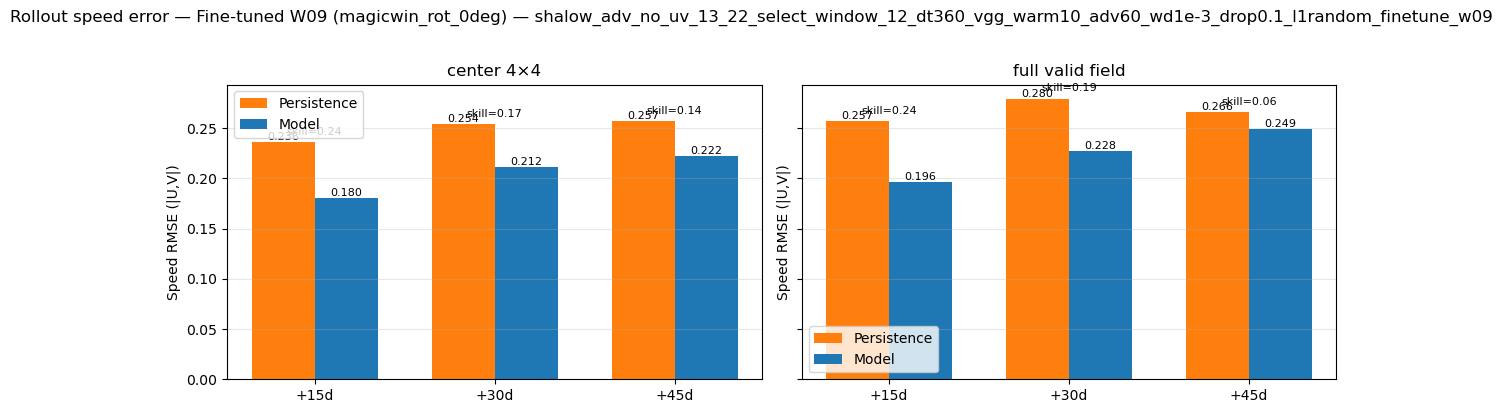

Saved: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/fineTuning/Test&Rollout/shalow_adv_no_uv_13_22_select_window_12_dt360_vgg_warm10_adv60_wd1e-3_drop0.1_l1random_finetune_w09__on__window_09/speed_rmse_center_and_full.png


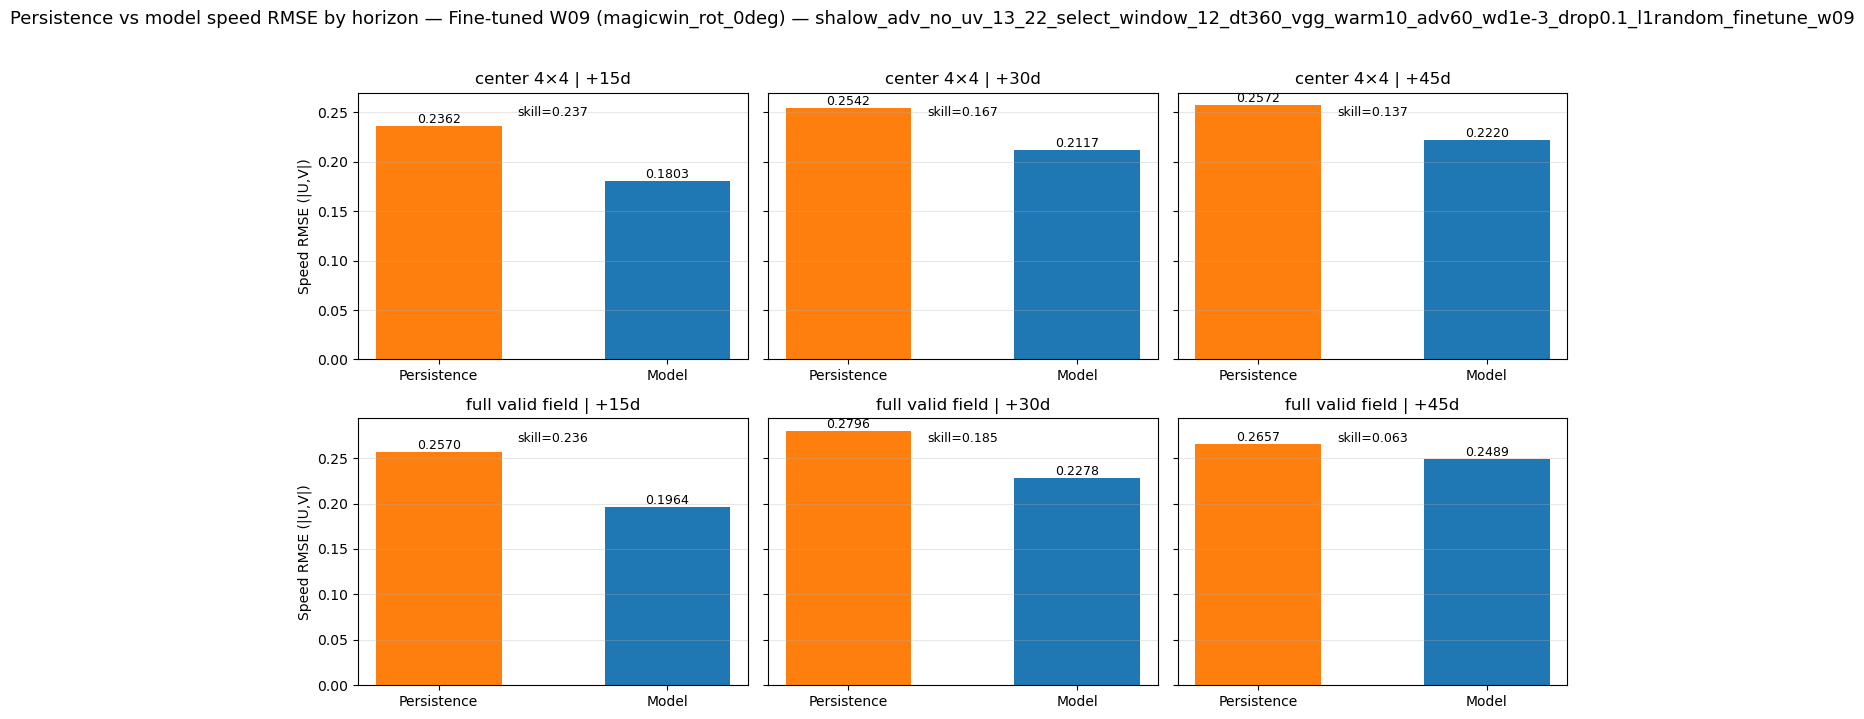

Saved: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/fineTuning/Test&Rollout/shalow_adv_no_uv_13_22_select_window_12_dt360_vgg_warm10_adv60_wd1e-3_drop0.1_l1random_finetune_w09__on__window_09/speed_rmse_by_horizon_center_and_full.png


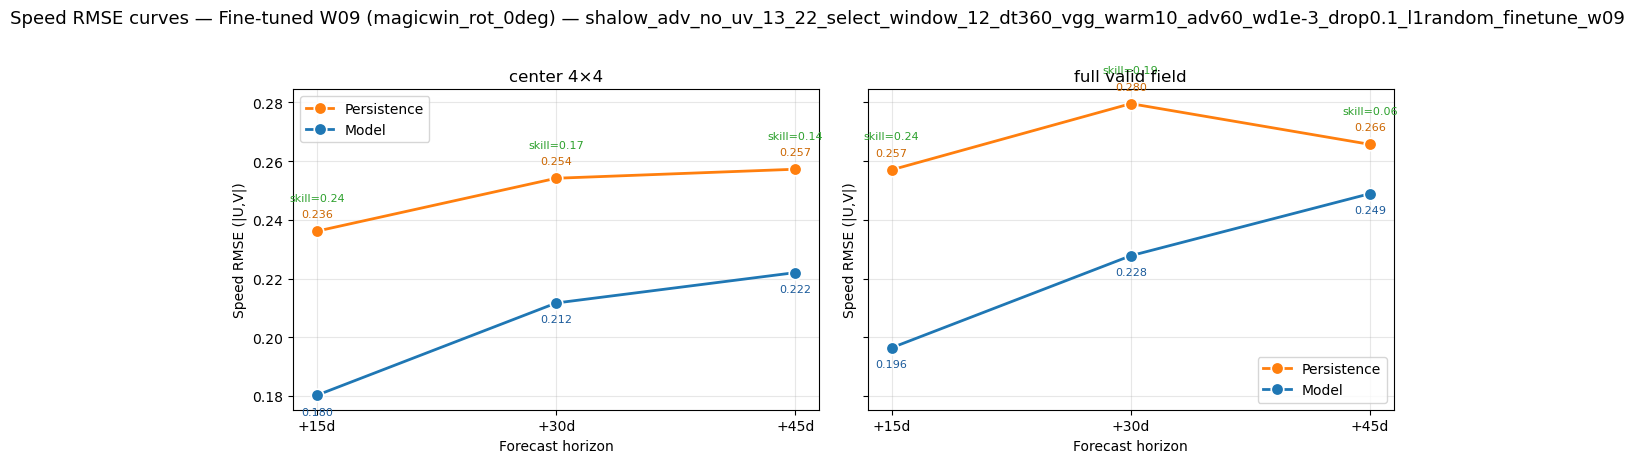

Saved: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/fineTuning/Test&Rollout/shalow_adv_no_uv_13_22_select_window_12_dt360_vgg_warm10_adv60_wd1e-3_drop0.1_l1random_finetune_w09__on__window_09/speed_rmse_curves_center_and_full.png


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone

SPEED_PATCH_SIZE = 4


def _center_slices(h: int, w: int, patch: int) -> tuple[slice, slice]:
    cy, cx = h // 2, w // 2
    half = patch // 2
    if patch % 2 == 0:
        return slice(cy - half, cy + half), slice(cx - half, cx + half)
    return slice(cy - half, cy + half + 1), slice(cx - half, cx + half + 1)


def _crop_metric_region(field: np.ndarray, mask: np.ndarray, patch_size: int | None):
    if patch_size is None:
        return field, mask
    sy, sx = _center_slices(field.shape[-2], field.shape[-1], patch_size)
    return field[..., sy, sx], mask[..., sy, sx]


def speed_magnitude(states) -> np.ndarray:
    arr = states.numpy() if torch.is_tensor(states) else np.asarray(states)
    return np.sqrt(arr[:, 0] ** 2 + arr[:, 1] ** 2)


def masked_rmse(field_a: np.ndarray, field_b: np.ndarray, mask: np.ndarray, patch_size: int | None = None) -> float:
    field_a, mask = _crop_metric_region(field_a, mask, patch_size)
    field_b, _ = _crop_metric_region(field_b, mask, patch_size)
    diff2 = (field_b - field_a) ** 2
    valid = mask == 0
    if not np.any(valid):
        return float("nan")
    return float(np.sqrt(diff2[valid].mean()))


def rollout_speed_metrics(
    gt_now, gt_h1, gt_h2, gt_h3, pred_h1, pred_h2, pred_h3, mask, horizons, patch_size: int | None = None,
):
    speed_now = speed_magnitude(gt_now)
    gt_speeds = [speed_magnitude(gt_h1), speed_magnitude(gt_h2), speed_magnitude(gt_h3)]
    pred_speeds = [speed_magnitude(pred_h1), speed_magnitude(pred_h2), speed_magnitude(pred_h3)]
    mask_np = mask.numpy() if torch.is_tensor(mask) else np.asarray(mask)
    rows = []
    for days, gt_spd, pred_spd in zip(horizons, gt_speeds, pred_speeds):
        persist = masked_rmse(speed_now, gt_spd, mask_np, patch_size)
        model_rmse = masked_rmse(pred_spd, gt_spd, mask_np, patch_size)
        skill = 1.0 - model_rmse / persist if persist > 0 else float("nan")
        rows.append(
            {
                "horizon_days": days,
                "persistence_rmse": persist,
                "model_rmse": model_rmse,
                "skill_score": skill,
            }
        )
    return rows


def print_metrics_table(metrics, region_label: str):
    print(f"\nSpeed RMSE (|U,V|) — {region_label}")
    print(f"{'Horizon':>10} {'Persistence':>14} {'Model':>14} {'Skill':>10}")
    print("-" * 52)
    for row in metrics:
        print(
            f"+{row['horizon_days']:>2}d"
            f" {row['persistence_rmse']:14.6f}"
            f" {row['model_rmse']:14.6f}"
            f" {row['skill_score']:10.3f}"
        )


metrics_center = rollout_speed_metrics(
    s3, s4, s5, s6, p1, p2, p3, mask_all, horizons=EVAL_HORIZONS, patch_size=SPEED_PATCH_SIZE,
)
metrics_full = rollout_speed_metrics(
    s3, s4, s5, s6, p1, p2, p3, mask_all, horizons=EVAL_HORIZONS, patch_size=None,
)

print_metrics_table(metrics_center, f"center {SPEED_PATCH_SIZE}x{SPEED_PATCH_SIZE}")
print_metrics_table(metrics_full, "full valid field")
rollout_title = f"Fine-tuned W{FINETUNE_WINDOW:02d} ({CATALOG_EXPORT_KEY}) — {MODEL_RUN_NAME}"

persist_center = [row["persistence_rmse"] for row in metrics_center]
model_center = [row["model_rmse"] for row in metrics_center]
skill_center = [row["skill_score"] for row in metrics_center]
persist_full = [row["persistence_rmse"] for row in metrics_full]
model_full = [row["model_rmse"] for row in metrics_full]
skill_full = [row["skill_score"] for row in metrics_full]

rollout_results = {
    "rollout_name": f"{MODEL_RUN_NAME}__on__window_{FINETUNE_WINDOW:02d}",
    "model_run_name": MODEL_RUN_NAME,
    "model_run_dir": str(MODEL_RUN_DIR),
    "finetune_window_number": FINETUNE_WINDOW,
    "finetune_window_slot": WINDOW_SLOT,
    "catalog_export_key": CATALOG_EXPORT_KEY,
    "test_data_prefix": TEST_DATA_PREFIX,
    "eval_horizons_days": list(EVAL_HORIZONS),
    "speed_patch_size": SPEED_PATCH_SIZE,
    "metrics_center": metrics_center,
    "metrics_full": metrics_full,
    "n_test_snapshots": int(n_snap),
    "evaluated_at": datetime.now(timezone.utc).isoformat(),
}
results_path = save_rollout_results(TEST_ROLLOUT_DIR, rollout_results)
print(f"\nSaved: {results_path}")

# --- Bar plots: RMSE values + skill labels ---
labels = [f"+{d}d" for d in EVAL_HORIZONS]
x = np.arange(len(labels))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, persist, model, skill, title in [
    (axes[0], persist_center, model_center, skill_center, f"center {SPEED_PATCH_SIZE}×{SPEED_PATCH_SIZE}"),
    (axes[1], persist_full, model_full, skill_full, "full valid field"),
]:
    ax.bar(x - width / 2, persist, width, label="Persistence", color="#ff7f0e")
    ax.bar(x + width / 2, model, width, label="Model", color="#1f77b4")
    ax.set_xticks(x, labels)
    ax.set_ylabel("Speed RMSE (|U,V|)")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, axis="y", alpha=0.3)
    for i, (p, m, s) in enumerate(zip(persist, model, skill)):
        ax.text(i - width / 2, p, f"{p:.3f}", ha="center", va="bottom", fontsize=8)
        ax.text(i + width / 2, m, f"{m:.3f}", ha="center", va="bottom", fontsize=8)
        ax.text(i, max(p, m) * 1.02, f"skill={s:.2f}", ha="center", va="bottom", fontsize=8)

fig.suptitle(f"Rollout speed error — {rollout_title}", y=1.02)
plt.tight_layout()
plot_path = TEST_ROLLOUT_DIR / "speed_rmse_center_and_full.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {plot_path}")

# --- Per-horizon panels ---
bar_w = 0.55
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey="row")
region_rows = [
    (persist_center, model_center, skill_center, f"center {SPEED_PATCH_SIZE}×{SPEED_PATCH_SIZE}"),
    (persist_full, model_full, skill_full, "full valid field"),
]
for row, (persist, model, skill, row_title) in enumerate(region_rows):
    for col, (days, p, m, s) in enumerate(zip(EVAL_HORIZONS, persist, model, skill)):
        ax = axes[row, col]
        bars = ax.bar(["Persistence", "Model"], [p, m], color=["#ff7f0e", "#1f77b4"], width=bar_w)
        ax.set_title(f"{row_title} | +{days}d")
        ax.set_ylabel("Speed RMSE (|U,V|)" if col == 0 else "")
        ax.grid(True, axis="y", alpha=0.3)
        for bar, val in zip(bars, [p, m]):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                val,
                f"{val:.4f}",
                ha="center",
                va="bottom",
                fontsize=9,
            )
        ax.text(0.5, 0.95, f"skill={s:.3f}", ha="center", va="top", fontsize=9, transform=ax.transAxes)

fig.suptitle(f"Persistence vs model speed RMSE by horizon — {rollout_title}", y=1.02, fontsize=13)
plt.tight_layout()
horizon_path = TEST_ROLLOUT_DIR / "speed_rmse_by_horizon_center_and_full.png"
plt.savefig(horizon_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {horizon_path}")

# --- Line + point curves with RMSE + skill annotations ---
horizons = np.array(EVAL_HORIZONS, dtype=float)
xtick_labels = [f"+{int(d)}d" for d in horizons]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, persist, model, skill, title in [
    (axes[0], persist_center, model_center, skill_center, f"center {SPEED_PATCH_SIZE}×{SPEED_PATCH_SIZE}"),
    (axes[1], persist_full, model_full, skill_full, "full valid field"),
]:
    ax.plot(
        horizons, persist,
        "-o", color="#ff7f0e", linewidth=2, markersize=9,
        markerfacecolor="#ff7f0e", markeredgecolor="white", markeredgewidth=1.2,
        label="Persistence",
    )
    ax.plot(
        horizons, model,
        "-o", color="#1f77b4", linewidth=2, markersize=9,
        markerfacecolor="#1f77b4", markeredgecolor="white", markeredgewidth=1.2,
        label="Model",
    )
    for d, p, m, s in zip(horizons, persist, model, skill):
        ax.annotate(f"{p:.3f}", (d, p), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8, color="#cc6600")
        ax.annotate(f"{m:.3f}", (d, m), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color="#1a5a9a")
        y_top = max(p, m)
        ax.annotate(
            f"skill={s:.2f}", (d, y_top), textcoords="offset points", xytext=(0, 22),
            ha="center", fontsize=8, color="#2ca02c",
        )

    ax.set_xticks(horizons)
    ax.set_xticklabels(xtick_labels)
    ax.set_xlabel("Forecast horizon")
    ax.set_ylabel("Speed RMSE (|U,V|)")
    ax.set_title(title)
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)

fig.suptitle(f"Speed RMSE curves — {rollout_title}", y=1.02, fontsize=13)
plt.tight_layout()
curves_path = TEST_ROLLOUT_DIR / "speed_rmse_curves_center_and_full.png"
plt.savefig(curves_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {curves_path}")
